# Marketing Campaign Response Prediction & Customer Targeting

**Objective:** Build a classification model to predict whether a customer will subscribe to a bank term deposit, and use the findings to support better marketing campaign targeting.

**Level:** Intermediate  
**Models:** Logistic Regression and Random Forest  
**Dataset:** UCI Bank Marketing (`bank-additional-full.csv`)

### Project workflow
1. Understand and clean the data
2. Explore customer and campaign patterns
3. Create a small number of useful features
4. Split the data and prepare it for modelling
5. Train two classification models
6. Compare model performance
7. Translate findings into business recommendations

> **Important:** The `duration` variable is excluded from the prediction models. It records the length of the call and is only known after the call has happened. Including it would make the model unsuitable for targeting customers before a call.

## 1. Import libraries

We use Pandas and NumPy for data handling, Matplotlib for charts, and Scikit-learn for preprocessing, modelling and evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

pd.set_option("display.max_columns", None)

## 2. Load the dataset

Place the CSV file in the same folder as this notebook. The dataset is semicolon-separated, so we use `sep=";"`.

In [2]:
df = pd.read_csv(r"C:\Users\H P\OneDrive\Desktop\MY PROJECTS\MARKETING ANALYST\Marketing Campaign Response Prediction & Customer Targeting\bank-additional-full.csv", sep = ";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Understand the dataset

In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (41188, 21)

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Data types:


age                 int64
job                   str
marital               str
education             str
default               str
housing               str
loan                  str
contact               str
month                 str
day_of_week           str
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome              str
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                     str
dtype: object


Missing values:


age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


Duplicate rows: 12


## 4. Basic data cleaning

- Remove exact duplicate rows.
- Rename the target column to `target`.
- Convert the target from Yes/No to 1/0.
- Keep `unknown` as a category. It is a recorded value in this dataset, not necessarily a missing value.

In [4]:
df = df.drop_duplicates().copy()

df = df.rename(columns={"y": "target"})
df["target"] = df["target"].map({"yes": 1, "no": 0})

print("Shape after removing duplicates:", df.shape)
print("\nTarget counts:")
display(df["target"].value_counts())

print("\nTarget percentages:")
display((df["target"].value_counts(normalize=True) * 100).round(2))

Shape after removing duplicates: (41176, 21)

Target counts:


target
0    36537
1     4639
Name: count, dtype: int64


Target percentages:


target
0    88.73
1    11.27
Name: proportion, dtype: float64

## 5. Exploratory Data Analysis (EDA)

First, check how many customers subscribed and how many did not. This helps us understand whether the target classes are balanced.

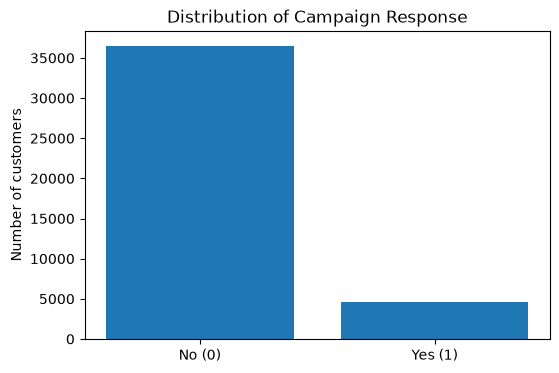

In [5]:
target_counts = df["target"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["No (0)", "Yes (1)"], target_counts.values)
plt.title("Distribution of Campaign Response")
plt.ylabel("Number of customers")
plt.show()

### 5.1 Subscription rate by age group

Age groups make the pattern easier to communicate than looking at every individual age.

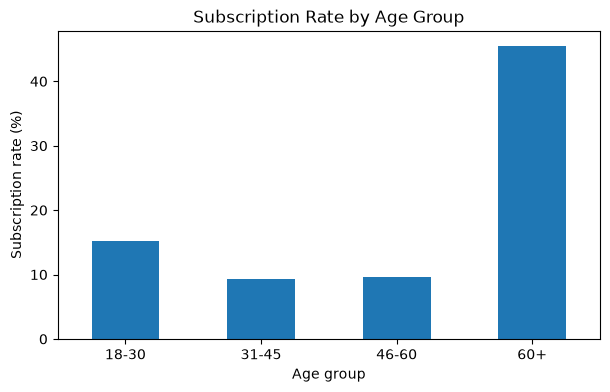

age_group
18-30    15.23
31-45     9.36
46-60     9.56
60+      45.54
Name: target, dtype: float64

In [6]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 30, 45, 60, 100],
    labels=["18-30", "31-45", "46-60", "60+"]
)

age_response = df.groupby("age_group", observed=False)["target"].mean() * 100

plt.figure(figsize=(7, 4))
age_response.plot(kind="bar")
plt.title("Subscription Rate by Age Group")
plt.xlabel("Age group")
plt.ylabel("Subscription rate (%)")
plt.xticks(rotation=0)
plt.show()

display(age_response.round(2))

### 5.2 Subscription rate by job category

This comparison can help identify customer groups that responded more often in this dataset.

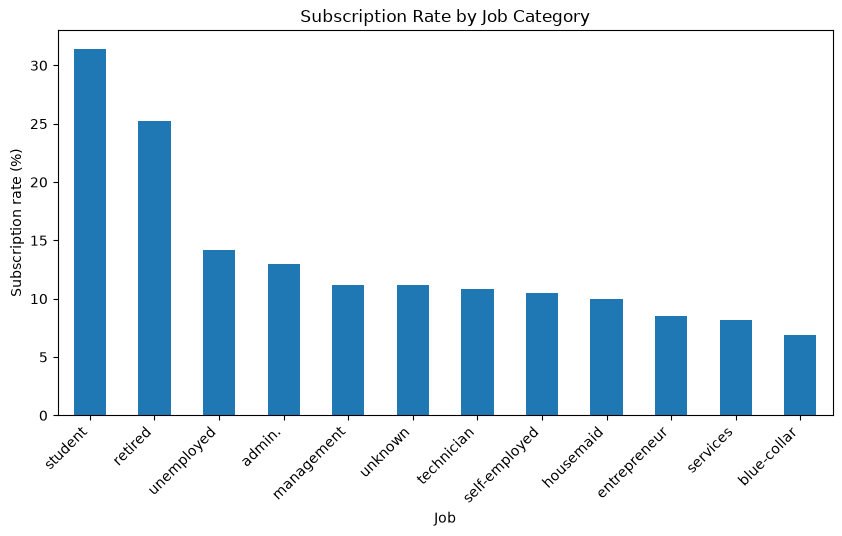

job
student          31.43
retired          25.26
unemployed       14.20
admin.           12.97
management       11.22
unknown          11.21
technician       10.83
self-employed    10.49
housemaid        10.00
entrepreneur      8.52
services          8.14
blue-collar       6.90
Name: target, dtype: float64

In [7]:
job_response = (df.groupby("job")["target"].mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
job_response.plot(kind="bar")
plt.title("Subscription Rate by Job Category")
plt.xlabel("Job")
plt.ylabel("Subscription rate (%)")
plt.xticks(rotation=45, ha="right")
plt.show()

display(job_response.round(2))

### 5.3 Subscription rate by education

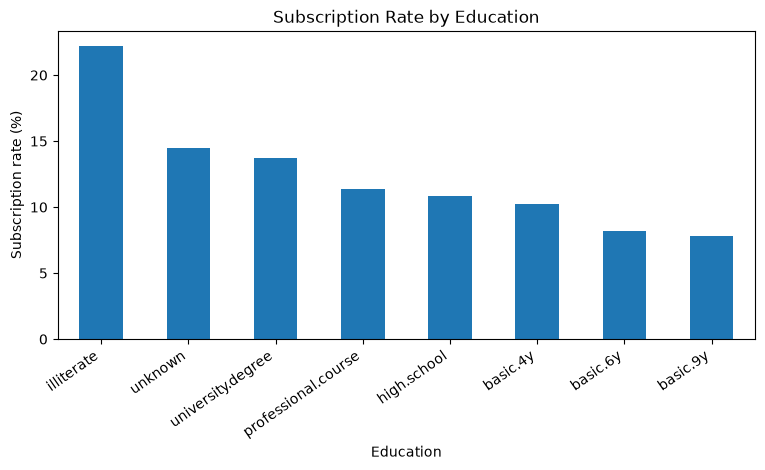

education
illiterate             22.22
unknown                14.51
university.degree      13.72
professional.course    11.35
high.school            10.84
basic.4y               10.25
basic.6y                8.21
basic.9y                7.82
Name: target, dtype: float64

In [8]:
education_response = (df.groupby("education")["target"].mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(9, 4))
education_response.plot(kind="bar")
plt.title("Subscription Rate by Education")
plt.xlabel("Education")
plt.ylabel("Subscription rate (%)")
plt.xticks(rotation=35, ha="right")
plt.show()

display(education_response.round(2))

### 5.4 Subscription rate by campaign month

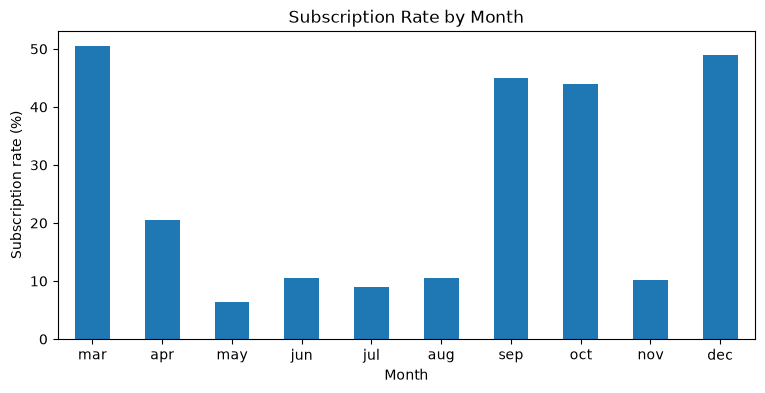

month
mar    50.55
apr    20.49
may     6.44
jun    10.51
jul     9.04
aug    10.61
sep    44.91
oct    43.93
nov    10.15
dec    48.90
Name: target, dtype: float64

In [9]:
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_response = (df.groupby("month")["target"].mean() * 100).reindex(month_order)

plt.figure(figsize=(9, 4))
month_response.plot(kind="bar")
plt.title("Subscription Rate by Month")
plt.xlabel("Month")
plt.ylabel("Subscription rate (%)")
plt.xticks(rotation=0)
plt.show()

display(month_response.round(2))

## 6. Simple feature engineering

The value `999` in `pdays` means that the customer was not previously contacted in an earlier campaign. It is not a real number of days.

We create a simple indicator called `previously_contacted` and then remove `pdays`. This avoids treating 999 as an ordinary numeric value.

We also retain `age_group`, created during EDA, as a categorical feature.

In [10]:
df["previously_contacted"] = (df["pdays"] != 999).astype(int)

# Remove columns that are not appropriate for this prediction task.
# duration is known only after the call, so it would cause data leakage.
# pdays is replaced by the clearer previously_contacted indicator.
df = df.drop(columns=["duration", "pdays"])

df[["age", "age_group", "previously_contacted", "previous", "target"]].head()

,age,age_group,previously_contacted,previous,target
0,56,46-60,0,0,0
1,57,46-60,0,0,0
2,37,31-45,0,0,0
3,40,31-45,0,0,0
4,56,46-60,0,0,0


## 7. Prepare features and target

`X` contains the input variables and `y` contains the outcome we want to predict.

We split the data into 80% training data and 20% test data. `stratify=y` keeps the Yes/No proportion similar in both sets.

In [11]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).round(3))

print("\nTesting target proportions:")
display(y_test.value_counts(normalize=True).round(3))

Training set: (32940, 20)
Testing set: (8236, 20)

Training target proportions:


target
0    0.887
1    0.113
Name: proportion, dtype: float64


Testing target proportions:


target
0    0.887
1    0.113
Name: proportion, dtype: float64

## 8. Preprocess the data

Machine learning models require numerical inputs.

- Numerical columns: fill missing values with the median and standardise the values.
- Categorical columns: fill missing values with the most frequent category and apply one-hot encoding.

The preprocessing is fitted on the training data only. The same fitted transformations are then applied to the test data.

In [12]:
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'age_group']


C:\Users\H P\AppData\Local\Temp\ipykernel_17588\607411505.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()


## 9. Train the classification models

We train two models:

1. **Logistic Regression:** a useful baseline classification model.
2. **Random Forest:** combines multiple decision trees and can capture more complex patterns.

The target is imbalanced, so we use `class_weight="balanced"` to give more importance to the less frequent Yes class.

In [13]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Both models have been trained.")

Both models have been trained.


## 10. Evaluate model performance

We compare the models using:

- **Accuracy:** overall proportion of correct predictions.
- **Precision:** among customers predicted as Yes, how many actually subscribed?
- **Recall:** among customers who actually subscribed, how many did the model identify?
- **F1-score:** balance between precision and recall.
- **ROC-AUC:** ability to distinguish between the two classes across different thresholds.

Because the Yes class is the minority class, do not judge the models using accuracy alone.

In [14]:
def evaluate_model(model, X_test, y_test, model_name):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

results = pd.DataFrame([
    evaluate_model(logistic_model, X_test, y_test, "Logistic Regression"),
    evaluate_model(random_forest_model, X_test, y_test, "Random Forest")
])

display(results.round(3))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.830,0.358,0.642,0.460,0.800
1,Random Forest,0.861,0.423,0.633,0.507,0.812


### 10.1 Compare confusion matrices

The confusion matrix shows correct and incorrect predictions for each class.

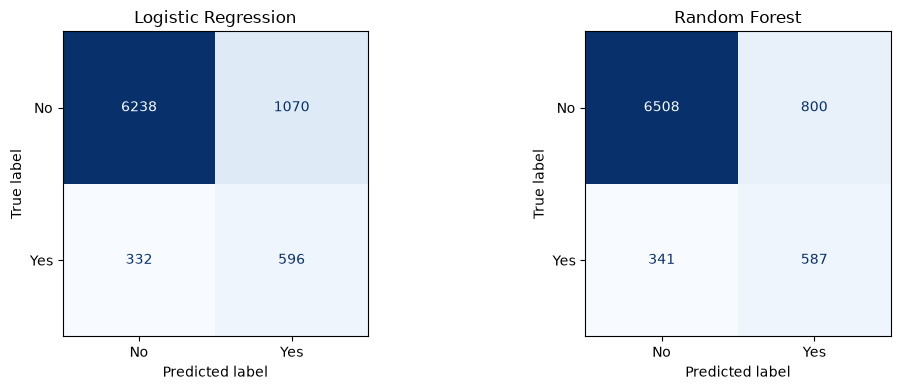

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, model, name in [
    (axes[0], logistic_model, "Logistic Regression"),
    (axes[1], random_forest_model, "Random Forest")
]:
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test,
        display_labels=["No", "Yes"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

### 10.2 Classification report

This gives precision, recall and F1-score separately for No and Yes.

In [16]:
for model, name in [
    (logistic_model, "Logistic Regression"),
    (random_forest_model, "Random Forest")
]:
    print("\n", name)
    print(classification_report(
        y_test,
        model.predict(X_test),
        target_names=["No", "Yes"],
        zero_division=0
    ))


 Logistic Regression
              precision    recall  f1-score   support

          No       0.95      0.85      0.90      7308
         Yes       0.36      0.64      0.46       928

    accuracy                           0.83      8236
   macro avg       0.65      0.75      0.68      8236
weighted avg       0.88      0.83      0.85      8236


 Random Forest
              precision    recall  f1-score   support

          No       0.95      0.89      0.92      7308
         Yes       0.42      0.63      0.51       928

    accuracy                           0.86      8236
   macro avg       0.69      0.76      0.71      8236
weighted avg       0.89      0.86      0.87      8236



### 10.3 ROC curves

The ROC curve compares the true positive rate with the false positive rate at different classification thresholds.

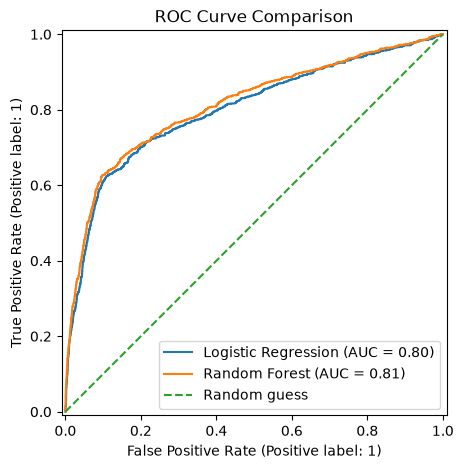

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_estimator(
    logistic_model, X_test, y_test, name="Logistic Regression", ax=ax
)
RocCurveDisplay.from_estimator(
    random_forest_model, X_test, y_test, name="Random Forest", ax=ax
)

ax.plot([0, 1], [0, 1], linestyle="--", label="Random guess")
ax.set_title("ROC Curve Comparison")
ax.legend()
plt.show()

## 11. Identify important features

For Random Forest, feature importance provides an indication of which input variables contributed most to the model's predictions.

Feature importance describes model behaviour; it does not prove that a variable causes a customer to subscribe.

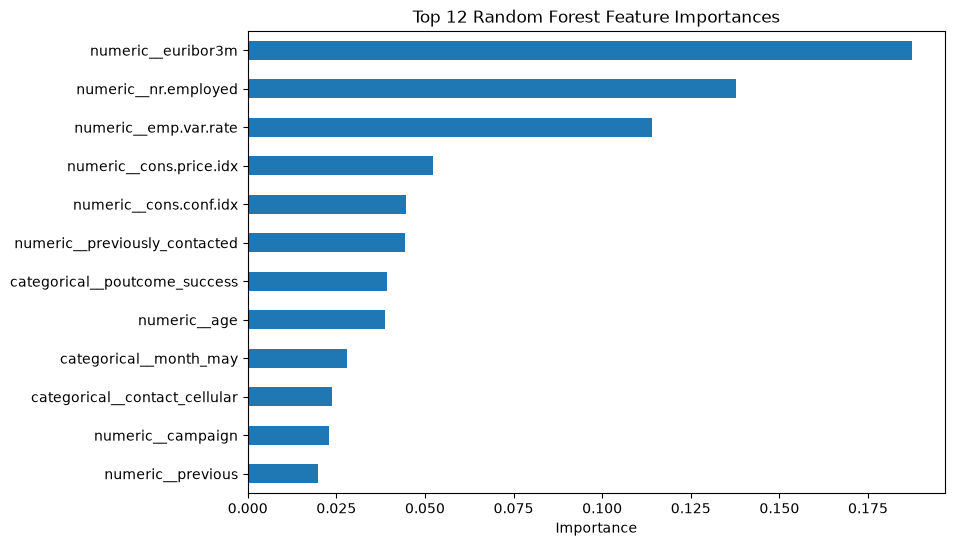

,Importance
numeric__euribor3m,0.187415
numeric__nr.employed,0.137627
numeric__emp.var.rate,0.114010
numeric__cons.price.idx,0.052206
numeric__cons.conf.idx,0.044623
numeric__previously_contacted,0.044367
categorical__poutcome_success,0.039275
numeric__age,0.038794
categorical__month_may,0.028006
categorical__contact_cellular,0.023665


In [18]:
# Get the fitted preprocessing step and the trained Random Forest classifier.
fitted_preprocessor = random_forest_model.named_steps["preprocessor"]
fitted_rf = random_forest_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
importance = pd.Series(
    fitted_rf.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

top_features = importance.head(12).sort_values()

plt.figure(figsize=(9, 6))
top_features.plot(kind="barh")
plt.title("Top 12 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.show()

display(importance.head(12).to_frame("Importance"))

## 12. Business interpretation and recommendations

Use the results from the EDA and model evaluation to prepare practical recommendations.

Examples of questions to answer:

1. Which customer groups show relatively higher subscription rates?
2. Which model identifies more actual subscribers (higher recall)?
3. What is the trade-off between identifying more potential subscribers and contacting customers who will not subscribe?
4. How could the bank use model scores to prioritise its calling list?

**Important:** A high recall model may identify more subscribers, but it may also generate more false positives. The bank should consider the cost of calls and the value of acquiring a subscriber before choosing a decision threshold.

The patterns in this dataset are associations, not proof of cause and effect.

In [19]:
# Display the strongest EDA segments for quick reference.
print("Subscription rate by age group (%):")
display(age_response.sort_values(ascending=False).round(2))

print("Subscription rate by job (%):")
display(job_response.head(5).round(2))

print("Subscription rate by month (%):")
display(month_response.sort_values(ascending=False).round(2))

print("Model comparison:")
display(results.set_index("Model").round(3))

Subscription rate by age group (%):


age_group
60+      45.54
18-30    15.23
46-60     9.56
31-45     9.36
Name: target, dtype: float64

Subscription rate by job (%):


job
student       31.43
retired       25.26
unemployed    14.20
admin.        12.97
management    11.22
Name: target, dtype: float64

Subscription rate by month (%):


month
mar    50.55
dec    48.90
sep    44.91
oct    43.93
apr    20.49
aug    10.61
jun    10.51
nov    10.15
jul     9.04
may     6.44
Name: target, dtype: float64

Model comparison:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.830,0.358,0.642,0.460,0.800
Random Forest,0.861,0.423,0.633,0.507,0.812


## 13. Final conclusion

This project used customer and campaign information to predict term-deposit subscription.

The workflow included data cleaning, exploratory analysis, simple feature engineering, preprocessing, two classification models and model evaluation.

The model comparison should be interpreted using precision, recall, F1-score and ROC-AUC rather than accuracy alone because the target classes are imbalanced.

The final model should be selected based on the bank's business objective. If the priority is to identify as many likely subscribers as possible, recall is important. If the bank wants to reduce unnecessary calls, precision also matters.

### Limitations
- The model is based on historical campaign data; customer behaviour may change over time.
- The results show associations and should not be interpreted as causal effects.
- A real deployment would require monitoring, validation on newer data and a business-approved decision threshold.